<a href="https://colab.research.google.com/github/tio22-png/Praktikum_PCVK_Hanggoro/blob/main/Modul2_PCVK_Hanggoro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Perbedaan cv2_imshow() dan plt.imshow() tanpa konversi warna
Jawaban: Hasilnya berbeda karena pustaka OpenCV (cv2) secara historis membaca dan menyimpan citra dalam urutan kanal warna BGR (Blue, Green, Red). Sebaliknya, Matplotlib (plt.imshow()) mengasumsikan bahwa array citra yang dimasukkan sudah berurutan RGB (Red, Green, Blue). Jika citra BGR langsung dimasukkan ke plt.imshow() tanpa dikonversi, kanal Merah dan Birunya akan tertukar, sehingga gambar terlihat kebiruan/kemerahan yang tidak wajar.

In [1]:
import cv2
import matplotlib.pyplot as plt

# Buka gambar foto aktivitas
img_bgr = cv2.imread('foto_aktivitas.jpg')

print("Membuktikan urutan BGR (B, G, R) pada pixel [0,0]:")
print("Nilai pixel dari cv2.imread :", img_bgr[0,0])

# Jika dikonversi ke RGB, urutan array angka pertama dan ketiga akan bertukar
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
print("Nilai pixel setelah di RGB-kan:", img_rgb[0,0])

Membuktikan urutan BGR (B, G, R) pada pixel [0,0]:
Nilai pixel dari cv2.imread : [166 177 181]
Nilai pixel setelah di RGB-kan: [181 177 166]


2. Perbandingan kanvas hitam int16 dan int32
Jawaban: Tampilan visual kedua kanvas tidak berbeda (keduanya tampak hitam pekat) karena nilai intensitas 0 pada kedua tipe data tersebut sama-sama merepresentasikan warna hitam. Namun, ukuran memori (nbytes) keduanya berbeda. Tipe data int16 (2 byte) mengonsumsi memori setengah lebih kecil dibandingkan int32 (4 byte) per pikselnya. Rentang nilai (min() dan max()) juga berbeda; int16 menampung dari –32.768 hingga 32.767, sedangkan int32 dari –2.147.483.648 hingga 2.147.483.647. Tipe int32 wajib digunakan saat menggambar larik titik polyline (cv2.polylines) di OpenCV.

In [2]:
import numpy as np

kanvas_16 = np.zeros((100, 100, 3), dtype=np.int16)
kanvas_32 = np.zeros((100, 100, 3), dtype=np.int32)

print("Kanvas int16: dtype=", kanvas_16.dtype, "| min=", np.min(kanvas_16), "| max (tipe)=", np.iinfo(kanvas_16.dtype).max, "| bytes=", kanvas_16.nbytes)
print("Kanvas int32: dtype=", kanvas_32.dtype, "| min=", np.min(kanvas_32), "| max (tipe)=", np.iinfo(kanvas_32.dtype).max, "| bytes=", kanvas_32.nbytes)

Kanvas int16: dtype= int16 | min= 0 | max (tipe)= 32767 | bytes= 60000
Kanvas int32: dtype= int32 | min= 0 | max (tipe)= 2147483647 | bytes= 120000


3. Kegunaan cv2_imshow dari google.colab.patches
Jawaban: Fungsi bawaan cv2.imshow() milik OpenCV membutuhkan eksekusi jendela antarmuka GUI (Graphical User Interface) pada sistem operasi lokal untuk menampilkan gambar. Karena Google Colab berbasis browser web dan berjalan di peladen awan (cloud), pemanggilan GUI lokal tidak dimungkinkan dan akan menyebabkan error sistem. Pustaka patch ini disediakan agar output citra dialihkan untuk dirender langsung sebagai output sel HTML/gambar di dalam browser.

4. skimage.io.imread() vs cv2.cvtColor()
Jawaban: Fungsi pembaca citra skimage.io.imread() secara native (bawaan) langsung membaca dan menyimpan array citra dalam format urutan RGB. Jika kita memaksakan fungsi cv2.cvtColor(img, cv2.COLOR_BGR2RGB) terhadap citra yang dihasilkan oleh skimage, kita justru secara keliru menukar kembali susunan yang sudah benar (RGB) menjadi BGR, sehingga warnanya menjadi terbalik dan salah.

In [3]:
from skimage import io
import cv2

# Otomatis RGB
img_ski = io.imread('foto_aktivitas.jpg')
# RGB ditukar jadi BGR secara keliru
img_salah = cv2.cvtColor(img_ski, cv2.COLOR_BGR2RGB)

print("Pixel [0,0] dari skimage (RGB Benar):", img_ski[0,0])
print("Pixel [0,0] setelah dipaksa cvtColor (Tertukar):", img_salah[0,0])

Pixel [0,0] dari skimage (RGB Benar): [181 177 166]
Pixel [0,0] setelah dipaksa cvtColor (Tertukar): [166 177 181]


5. figsize vs img.shape
Jawaban: Tidak, nilai img.shape tidak ikut berubah sama sekali. Parameter figsize pada plt.figure() hanya berfungsi mengatur ukuran kanvas visual/tampilan (dalam satuan inci) pada antarmuka layar saja. Ini berbeda dengan mengubah ukuran citra (misalnya memakai cv2.resize()), yang secara nyata menambah atau mengurangi jumlah piksel data di dalam memori komputer dan secara permanen mengubah nilai matriks citranya

Bagian 2: Tugas Praktikum - Penerapan

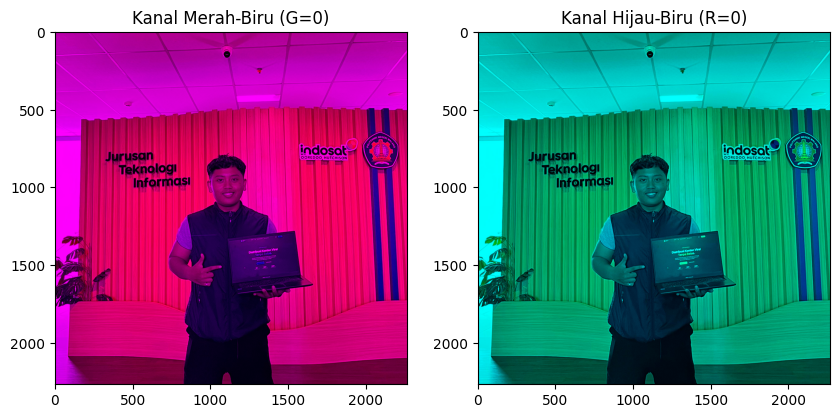

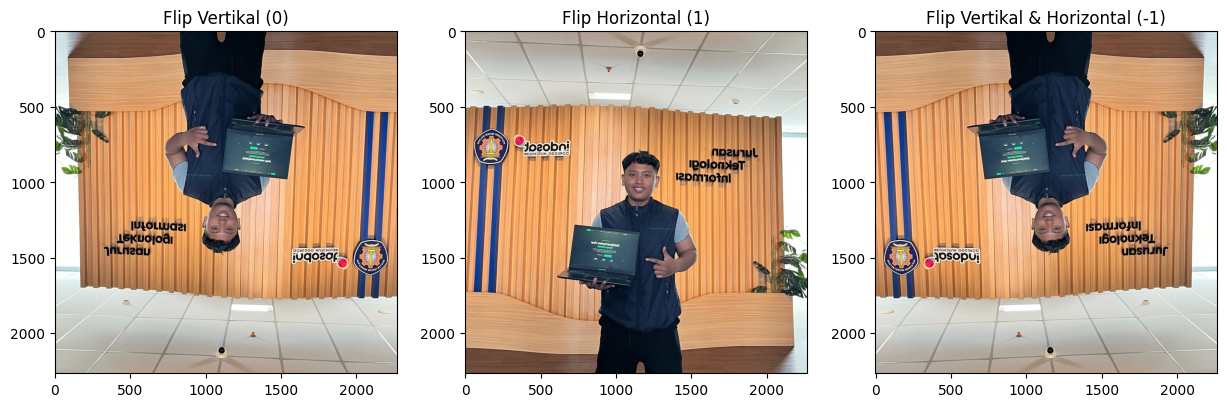

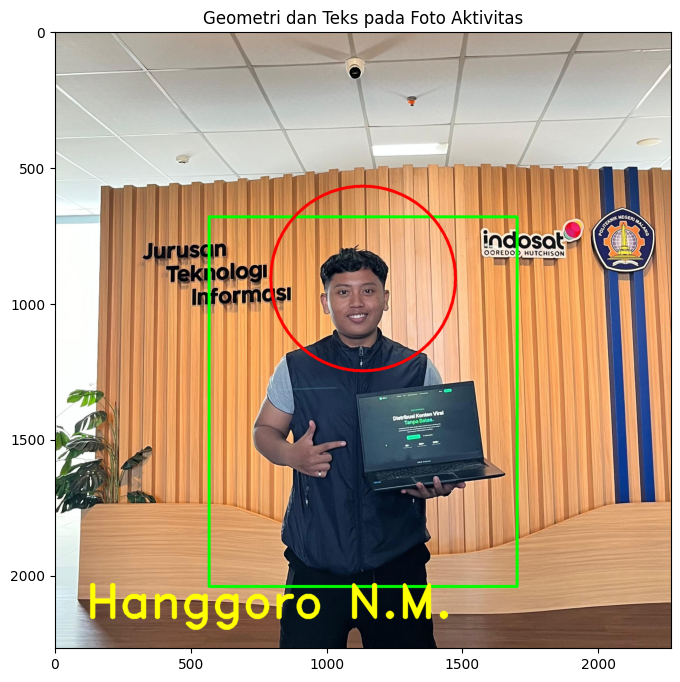

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Membaca citra dan konversi ke RGB
img = cv2.imread('foto_aktivitas.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# ==========================================
# Tugas 1: Kanal Merah-Biru dan Hijau-Biru
# ==========================================
# Salin citra asli (pengirisan pada NumPy menghasilkan view, gunakan copy agar aman)
img_rb = img.copy()
img_rb[:, :, 1] = 0 # Kanal indeks 1 (Hijau) dinolkan

img_gb = img.copy()
img_gb[:, :, 0] = 0 # Kanal indeks 0 (Merah) dinolkan

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_rb)
plt.title('Kanal Merah-Biru (G=0)')

plt.subplot(1, 2, 2)
plt.imshow(img_gb)
plt.title('Kanal Hijau-Biru (R=0)')
plt.show()

# ==========================================
# Tugas 2: Tiga Bentuk Pencerminan (Flip)
# ==========================================
# Pencerminan: 0 (Vertikal), 1 (Horizontal), -1 (Keduanya)
flip_vertikal = cv2.flip(img, 0)
flip_horizontal = cv2.flip(img, 1)
flip_keduanya = cv2.flip(img, -1)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(flip_vertikal)
plt.title('Flip Vertikal (0)')

plt.subplot(1, 3, 2)
plt.imshow(flip_horizontal)
plt.title('Flip Horizontal (1)')

plt.subplot(1, 3, 3)
plt.imshow(flip_keduanya)
plt.title('Flip Vertikal & Horizontal (-1)')
plt.show()

# ==========================================
# Tugas 3: Geometri dan Teks Kustom
# ==========================================
img_geo = img.copy()
h, w = img_geo.shape[:2] # Membaca resolusi dengan aman

# Menggambar Rectangle & Lingkaran adaptif di area tengah badan
cv2.rectangle(img_geo, (int(w*0.25), int(h*0.3)), (int(w*0.75), int(h*0.9)), (0, 255, 0), 10)
cv2.circle(img_geo, (int(w*0.5), int(h*0.4)), int(w*0.15), (255, 0, 0), 10)

# Menambahkan nama dengan font, skala, dan warna kustom
font = cv2.FONT_HERSHEY_DUPLEX
# Tepi halus dengan lineType=cv2.LINE_AA[cite: 2]
cv2.putText(img_geo, "Hanggoro N.M.", (int(w*0.05), int(h*0.95)), font, w/400, (255, 255, 0), max(1, int(w/200)), cv2.LINE_AA)

plt.figure(figsize=(8, 8))
plt.imshow(img_geo)
plt.title("Geometri dan Teks pada Foto Aktivitas")
plt.show()

Pertanyaan: Apakah melakukan kompresi pengubahan ukuran (downscaling) pada citra mengubah nilai rata-rata intensitas piksel secara signifikan?
Rancangan Program: Kita akan menghitung np.mean() (nilai rata-rata piksel) dari foto asli, lalu membandingkannya dengan nilai rata-rata foto yang sudah di-resize ukurannya menjadi sangat kecil menggunakan metode interpolasi INTER_AREA (yang direkomendasikan untuk downscaling)[cite: 2].

In [5]:
# TUGAS ANALISA
import cv2
import numpy as np

img_asli = cv2.imread('foto_aktivitas.jpg')
img_asli = cv2.cvtColor(img_asli, cv2.COLOR_BGR2RGB)

# Resize menjadi 5% dari ukuran asli menggunakan INTER_AREA[cite: 2]
h, w = img_asli.shape[:2]
img_kecil = cv2.resize(img_asli, (int(w*0.05), int(h*0.05)), interpolation=cv2.INTER_AREA)

# Hitung Rata-rata
mean_asli = np.mean(img_asli)
mean_kecil = np.mean(img_kecil)

print(f"Rata-rata intensitas piksel foto asli  : {mean_asli:.2f}")
print(f"Rata-rata intensitas piksel foto kecil : {mean_kecil:.2f}")
print(f"Selisih pergeseran nilai rata-rata     : {abs(mean_asli - mean_kecil):.2f}")

# Kesimpulan akan muncul otomatis di output saat di print:
print("\nKesimpulan: Mengubah ukuran piksel (resize) akan memodifikasi/menghilangkan beberapa data asli.")
print("Nilai rata-rata piksel (mean intensity) akan bergeser, meskipun perubahannya biasanya kecil.")

Rata-rata intensitas piksel foto asli  : 146.50
Rata-rata intensitas piksel foto kecil : 146.51
Selisih pergeseran nilai rata-rata     : 0.00

Kesimpulan: Mengubah ukuran piksel (resize) akan memodifikasi/menghilangkan beberapa data asli.
Nilai rata-rata piksel (mean intensity) akan bergeser, meskipun perubahannya biasanya kecil.


Bagian 4: Tugas Praktikum - Aplikasi (Adaptif)

--- UJI COBA FOTO POTRET ---


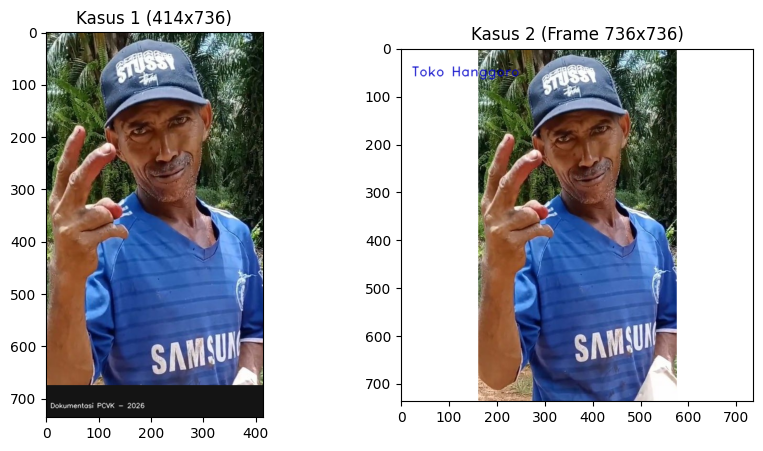


--- UJI COBA FOTO LANSKAP ---


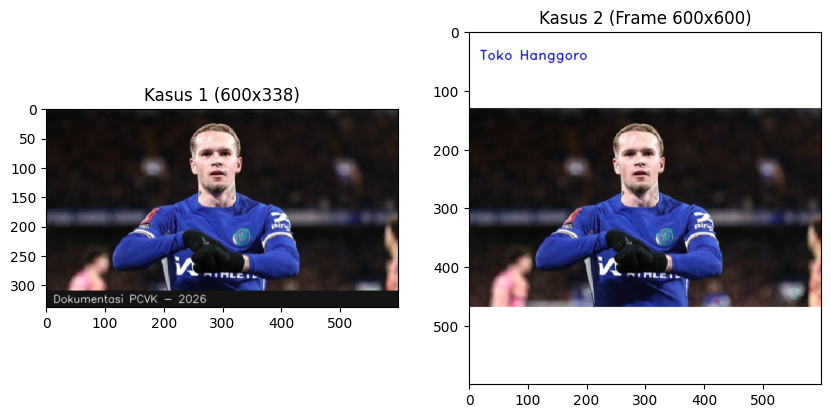

In [6]:
# ==========================================
# Studi Kasus 1 & 2: Bar Identitas & Thumbnail 1:1 (Fungsi Adaptif)
# ==========================================
import cv2
import numpy as np
import matplotlib.pyplot as plt

def proses_gambar_adaptif(nama_file, nama_toko):
    # Membaca citra
    img = cv2.imread(nama_file)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    # --- KASUS 1: BAR IDENTITAS ADAPTIF ---
    img_k1 = img.copy()
    # Menghitung proporsi secara adaptif berdasarkan ukuran asli[cite: 2]
    tinggi_bar = int(h / 12)  # Tinggi bar selalu 1/12 dari tinggi gambar
    skala_font_k1 = w / 1000
    tebal_k1 = max(1, int(w / 500))

    # Menggambar bar hitam di bagian bawah (-1 artinya blok padat/terisi penuh)[cite: 2]
    cv2.rectangle(img_k1, (0, h - tinggi_bar), (w, h), (20, 20, 20), -1)
    # Teks (Dokumentasi PCVK - 2026) rata kiri di dalam bar
    cv2.putText(img_k1, "Dokumentasi PCVK - 2026", (int(w*0.02), int(h - tinggi_bar/3.5)),
                cv2.FONT_HERSHEY_SIMPLEX, skala_font_k1, (255, 255, 255), tebal_k1, cv2.LINE_AA)

    # --- KASUS 2: THUMBNAIL 1:1 PERSEGI ---
    # Mencari sisi terpanjang untuk dijadikan ukuran bingkai persegi
    sisi_max = max(h, w)

    # Membuat kanvas kosong berbentuk persegi 1:1, latar warna putih (255) dengan uint8[cite: 2]
    kanvas = np.full((sisi_max, sisi_max, 3), 255, dtype=np.uint8)

    # Menghitung titik tengah kordinat (offset) agar gambar jatuh persis di tengah
    y_off = (sisi_max - h) // 2
    x_off = (sisi_max - w) // 2
    kanvas[y_off : y_off + h, x_off : x_off + w] = img

    # Menambahkan logo teks nama toko secara adaptif di pojok kiri atas
    skala_font_k2 = sisi_max / 800
    tebal_k2 = max(1, int(sisi_max / 400))
    cv2.putText(kanvas, nama_toko, (int(sisi_max*0.03), int(sisi_max*0.08)),
                cv2.FONT_HERSHEY_DUPLEX, skala_font_k2, (0, 0, 200), tebal_k2, cv2.LINE_AA)

    # Menampilkan hasil
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img_k1)
    plt.title(f"Kasus 1 ({w}x{h})")

    plt.subplot(1, 2, 2)
    plt.imshow(kanvas)
    plt.title(f"Kasus 2 (Frame {sisi_max}x{sisi_max})")
    plt.show()

# Panggil fungsi untuk menguji gambar Potret (Bapak berkaos biru)
print("--- UJI COBA FOTO POTRET ---")
proses_gambar_adaptif('bebas_potret.jpg', "Toko Hanggoro")

# Panggil fungsi untuk menguji gambar Lanskap (Pemain Bola)
print("\n--- UJI COBA FOTO LANSKAP ---")
proses_gambar_adaptif('bebas_lanskap.jpg', "Toko Hanggoro")